In [112]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import pearsonr
plt.style.use("seaborn-v0_8-whitegrid")
print(plt.style.available)


['Solarize_Light2', 'bmh', 'classic', 'dark_background', 'fast', 'fivethirtyeight', 'ggplot', 'grayscale', 'petroff10', 'petroff6', 'petroff8', 'seaborn-v0_8', 'seaborn-v0_8-bright', 'seaborn-v0_8-colorblind', 'seaborn-v0_8-dark', 'seaborn-v0_8-dark-palette', 'seaborn-v0_8-darkgrid', 'seaborn-v0_8-deep', 'seaborn-v0_8-muted', 'seaborn-v0_8-notebook', 'seaborn-v0_8-paper', 'seaborn-v0_8-pastel', 'seaborn-v0_8-poster', 'seaborn-v0_8-talk', 'seaborn-v0_8-ticks', 'seaborn-v0_8-white', 'seaborn-v0_8-whitegrid', 'tableau-colorblind10']


https://www.kaggle.com/datasets/thebumpkin/10400-classic-hits-10-genres-1923-to-2023


# ¿ Sueñan los androides con estudios culturales?

Spotify obtiene indicadores mediante algoritmos de análisis de audio que procesan las características acústicas de cada canción, como el ritmo, la intensidad, el tempo, la estructura sonora y las propiedades espectrales. A partir de estos parámetros, sus modelos estiman diferentes atributos musicales y los transforman en valores normalizados entre 0 y 1. Estos valores no proceden de votaciones de los usuarios ni de valoraciones subjetivas, sino de modelos computacionales desarrollados por Spotify. Cada indicador mide una dimensión diferente: por ejemplo, Energy estima la intensidad y actividad percibida, Danceability la adecuación rítmica para bailar y Valence el carácter emocional positivo o negativo de la música.

Basdonos en ellos  vamos analizar un CSV con 15.000 hits. Analizaremos la evolución de la música en clave sociohistórica, haciendo un mix entre ciencia de datos y estudios culturales. 

## H1. Ni la clave ni el modo (menor y mayor infuyen en como percibe el API de Sporty a las canciones.

## H2. Cambios en la música
- **En los últimos 40 años las grabaciones músciales han ido adquiriendo más volumen , más energía y una vibra menos postiva.Cada género tiene atributos propios. La prevalencia de cada género puede ir variando con el paso del tiempo.Por ello vamos a centrarnos que ocurrio con el género del Metal. Compararemos el Pop y música de acutalidd y el Resto de Géneros.:**


## H3. El mismo ciclo sociopolítoco puede llegar afectar de manera diferente a como se compone  música en función del género
- ** Miraremos como en un mismo perodio historico hay géneros con tendencias contradictorias** 
## H4. No éxite una receta para el exito
- **Los atributos que hacen que una cancion sea popular varian en funcion del género:**


| Variable         | Rango habitual    | Significado                                       |
| ---------------- | ----------------- | ------------------------------------------------- |
| Danceability     | 0 – 1             | Facilidad para bailar.                            |
| Energy           | 0 – 1             | Intensidad y actividad de la canción.             |
| Loudness         | -60 – 0 dB aprox. | Volumen percibido de la grabación.                |
| Speechiness      | 0 – 1             | Presencia de palabras habladas.                   |
| Acousticness     | 0 – 1             | Probabilidad de que sea acústica.                 |
| Instrumentalness | 0 – 1             | Probabilidad de que no tenga voces.               |
| Liveness         | 0 – 1             | Probabilidad de que sea una grabación en directo. |
| Valence          | 0 – 1             | Positividad emocional percibida.                  |
| Tempo            | BPM               | Velocidad de la canción.                          |
| Duration         | Milisegundos      | Duración original de la canción.                  



In [113]:
df = pd.read_csv("ClassicHit.csv")

In [114]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15150 entries, 0 to 15149
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Track             15150 non-null  str    
 1   Artist            15150 non-null  str    
 2   Year              15150 non-null  int64  
 3   Duration          15150 non-null  int64  
 4   Time_Signature    15150 non-null  int64  
 5   Danceability      15150 non-null  float64
 6   Energy            15150 non-null  float64
 7   Key               15150 non-null  int64  
 8   Loudness          15150 non-null  float64
 9   Mode              15150 non-null  int64  
 10  Speechiness       15150 non-null  float64
 11  Acousticness      15150 non-null  float64
 12  Instrumentalness  15150 non-null  float64
 13  Liveness          15150 non-null  float64
 14  Valence           15150 non-null  float64
 15  Tempo             15150 non-null  float64
 16  Popularity        15150 non-null  int64  
 17  Genr

In [115]:
df.groupby("Genre")["Year"].max()


Genre
Alt. Rock    2018
Blues        2022
Country      2023
Disco        2020
EDM          2024
Folk         2023
Funk         2023
Gospel       2022
Jazz         2015
Metal        2022
Pop          1999
Punk         2023
R&B          2016
Rap          2023
Reggae       2018
Rock         2024
SKA          2020
Today        2023
World        2019
Name: Year, dtype: int64

In [116]:
df.groupby("Genre")["Year"].min()

Genre
Alt. Rock    1964
Blues        1923
Country      1927
Disco        1967
EDM          1991
Folk         1939
Funk         1959
Gospel       1959
Jazz         1899
Metal        1968
Pop          1950
Punk         1969
R&B          1938
Rap          1982
Reggae       1965
Rock         1962
SKA          1960
Today        2001
World        1958
Name: Year, dtype: int64

## Limpeza

In [117]:
df = df[df["Year"] > 1980]
df = df[df["Year"] < 2020]


## Variable de años en categorias

In [118]:
df["Yearcat"] = pd.cut(
    df["Year"],
    bins=[1979, 1990, 2005, 2020],
    labels=["1980-1990", "1991-2005", "2006-2020"]
)

### Creamos una nueva categoría de géneros


Por un lado tendremos la categoría metal. Por el otro tenemos al Pop y a la música de hoy en dia


In [119]:

df["Genre2"] = np.select(
    [
        df["Genre"] == "Metal",
        df["Genre"].isin(["Pop", "Today"])
    ],
    [
        "Metal",
        "Pop/Today"
    ],
    default="Resto de géneros"
)


## Variables categoricas

In [120]:
df["Time_Signature"] = df["Time_Signature"].astype(str)
df["Key"] = df["Key"].astype(str)
df["Mode_ascat"] = df["Mode"].astype(str)

## Pasar las variables de la API de Spoty a escala 100
Las variabels de la API de spoty están pensandas para una maquina.
Para que sean más legible para los humanos lo multiplicaremos por 100.
Asi mismo nos da el tiempo en milisegundos. Por ello multiplicamos por mil y dividimos por 60. Así tenemos el tiempo en inteligibles minutos

In [121]:
#df = df[df["Genre"].isin(["Metal", "Punk","Alt. Rock","Rock"])]
#df = df[df["Genre"].isin(["Metal"])]

df["Duration"] = (df["Duration"]/1000) /60


df["Valence"] = df["Valence"] *100
df["Energy"] = df["Energy"] *100
df["Danceability"] = df["Danceability"] *100
df["Speechiness"] = df["Speechiness"] *100
df["Acousticness"] = df["Acousticness"] *100
df["Instrumentalness"] = df["Instrumentalness"] *100
df["Liveness"] = df["Liveness"] *100



## Inciamos lo descriptivo
### Mapa mediana variables api spoty

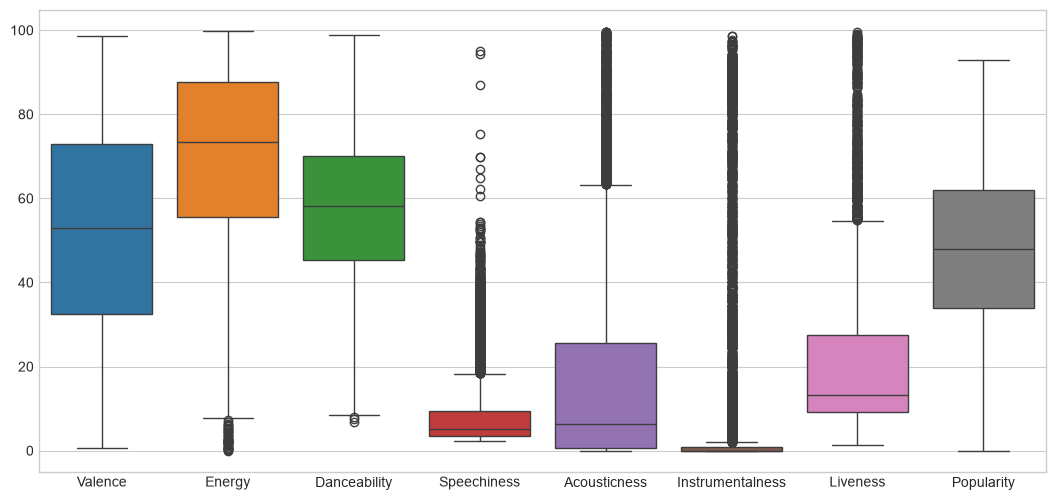

In [122]:
plt.figure(figsize=(13, 6))  # (ancho, alto) en pulgadas
sns.boxplot(data=df[["Valence","Energy","Danceability","Speechiness","Acousticness","Instrumentalness","Liveness","Popularity"]])
plt.show()

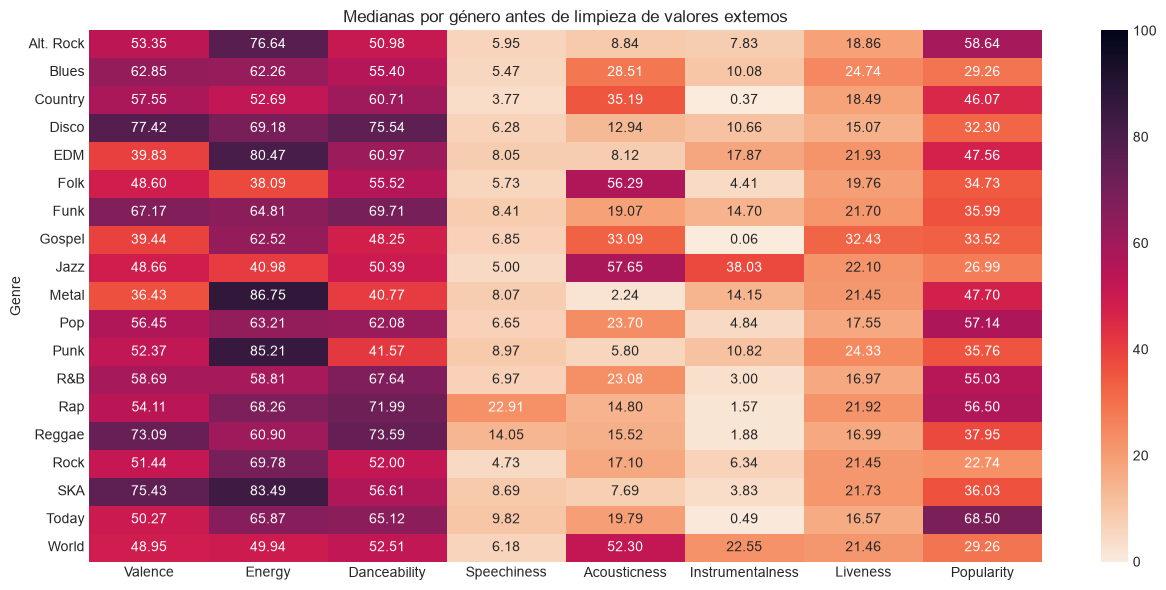

In [123]:
medianas = df.groupby("Genre")[["Valence","Energy","Danceability","Speechiness","Acousticness","Instrumentalness","Liveness","Popularity"]].mean()

# Representar mapa de calor
plt.figure(figsize=(13, 6))  # (ancho, alto) en pulgadas
sns.heatmap(
    medianas,
    annot=True,
    cmap= "rocket_r",
    fmt='.2f',
    linewidths=0,
    vmin= 0,
    vmax=100,
    center=50
)
plt.title("Medianas por género antes de limpieza de valores extemos")
plt.tight_layout()
plt.show()

La calve de la canción parece no afectar a los criterios de la API de Spotify

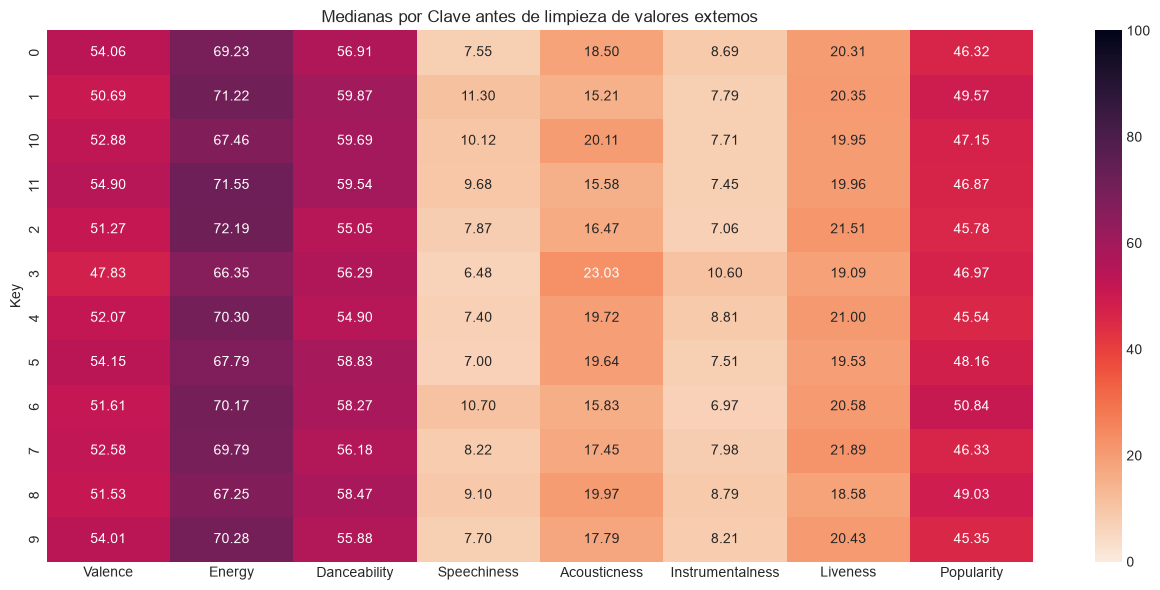

In [124]:
medianas = df.groupby("Key")[["Valence","Energy","Danceability","Speechiness","Acousticness","Instrumentalness","Liveness","Popularity"]].mean()

# Representar mapa de calor
plt.figure(figsize=(13, 6))  # (ancho, alto) en pulgadas
sns.heatmap(
    medianas,
    annot=True,
    cmap= "rocket_r",
    fmt='.2f',
    linewidths=0,
    vmin= 0,
    vmax=100,
    center=50
)
plt.title("Medianas por Clave antes de limpieza de valores extemos")
plt.tight_layout()
plt.show()

El modo no parece incidir en estos criterios

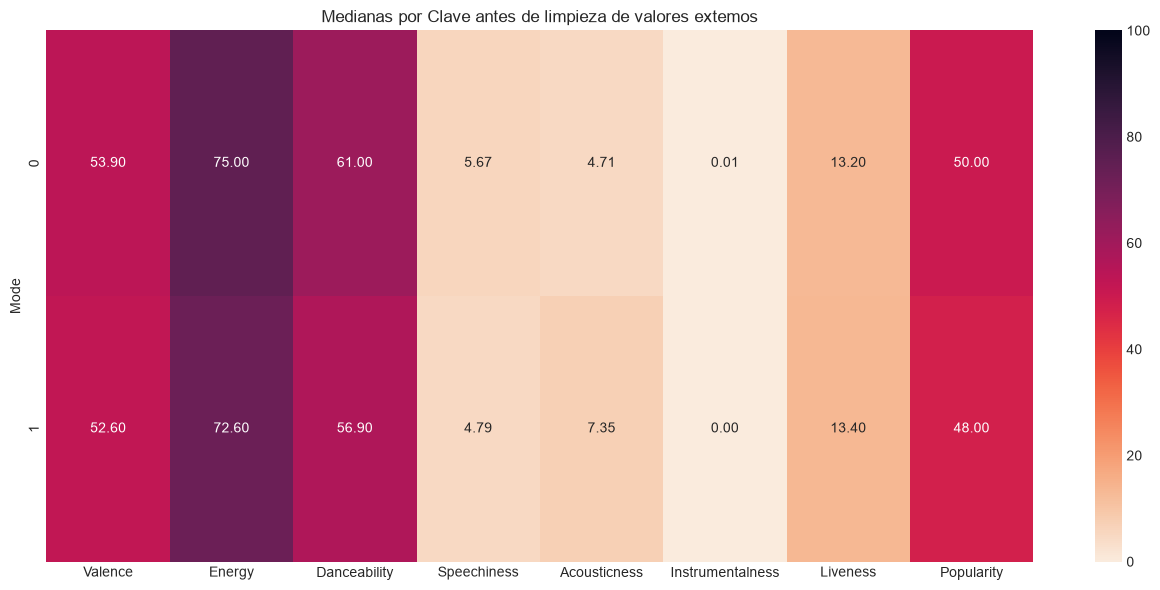

In [125]:
medianas = df.groupby("Mode")[["Valence","Energy","Danceability","Speechiness","Acousticness","Instrumentalness","Liveness","Popularity"]].median()

# Representar mapa de calor
plt.figure(figsize=(13, 6))  # (ancho, alto) en pulgadas
sns.heatmap(
    medianas,
    annot=True,
    cmap= "rocket_r",
    fmt='.2f',
    linewidths=0,
    vmin= 0,
    vmax=100,
    center=50
)
plt.title("Medianas por Clave antes de limpieza de valores extemos")
plt.tight_layout()
plt.show()

### Quitar valores extremos

In [126]:

#df = df[df["Duration"] < 10]
#df = df[df["Tempo"] > 50]
#df = df[df["Loudness"] > -15]
#df = df[df["Energy"] > 20]
#df = df[df["Instrumentalness"] < 1]
#df = df[df["Speechiness"] < 20]
#df = df[df["Liveness"] < 60]

df.info()



<class 'pandas.DataFrame'>
Index: 7899 entries, 0 to 15149
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   Track             7899 non-null   str     
 1   Artist            7899 non-null   str     
 2   Year              7899 non-null   int64   
 3   Duration          7899 non-null   float64 
 4   Time_Signature    7899 non-null   str     
 5   Danceability      7899 non-null   float64 
 6   Energy            7899 non-null   float64 
 7   Key               7899 non-null   str     
 8   Loudness          7899 non-null   float64 
 9   Mode              7899 non-null   int64   
 10  Speechiness       7899 non-null   float64 
 11  Acousticness      7899 non-null   float64 
 12  Instrumentalness  7899 non-null   float64 
 13  Liveness          7899 non-null   float64 
 14  Valence           7899 non-null   float64 
 15  Tempo             7899 non-null   float64 
 16  Popularity        7899 non-null   int64

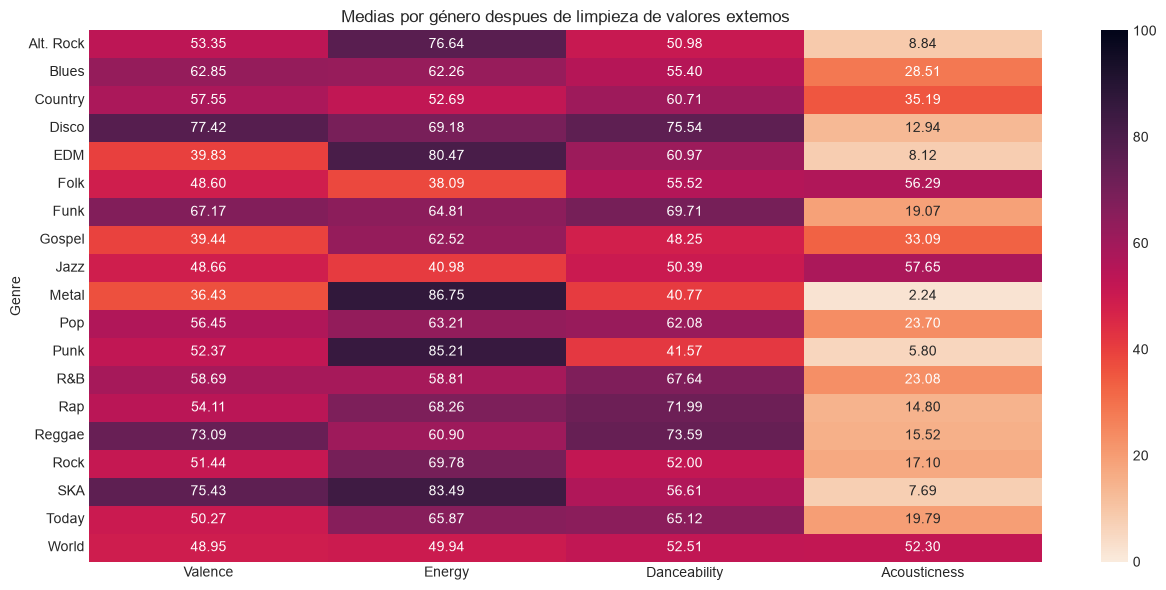

In [127]:
medias = df.groupby("Genre")[["Valence","Energy","Danceability","Acousticness"]].mean()

# Representar mapa de calor
plt.figure(figsize=(13, 6))  # (ancho, alto) en pulgadas
sns.heatmap(
    medias,
    annot=True,
    cmap= "rocket_r",
    fmt='.2f',
    linewidths=0,
    vmin= 0,
    vmax=100,
    center=50
)

plt.title("Medias por género despues de limpieza de valores extemos")
plt.tight_layout()
plt.show()

<Axes: xlabel='Year'>

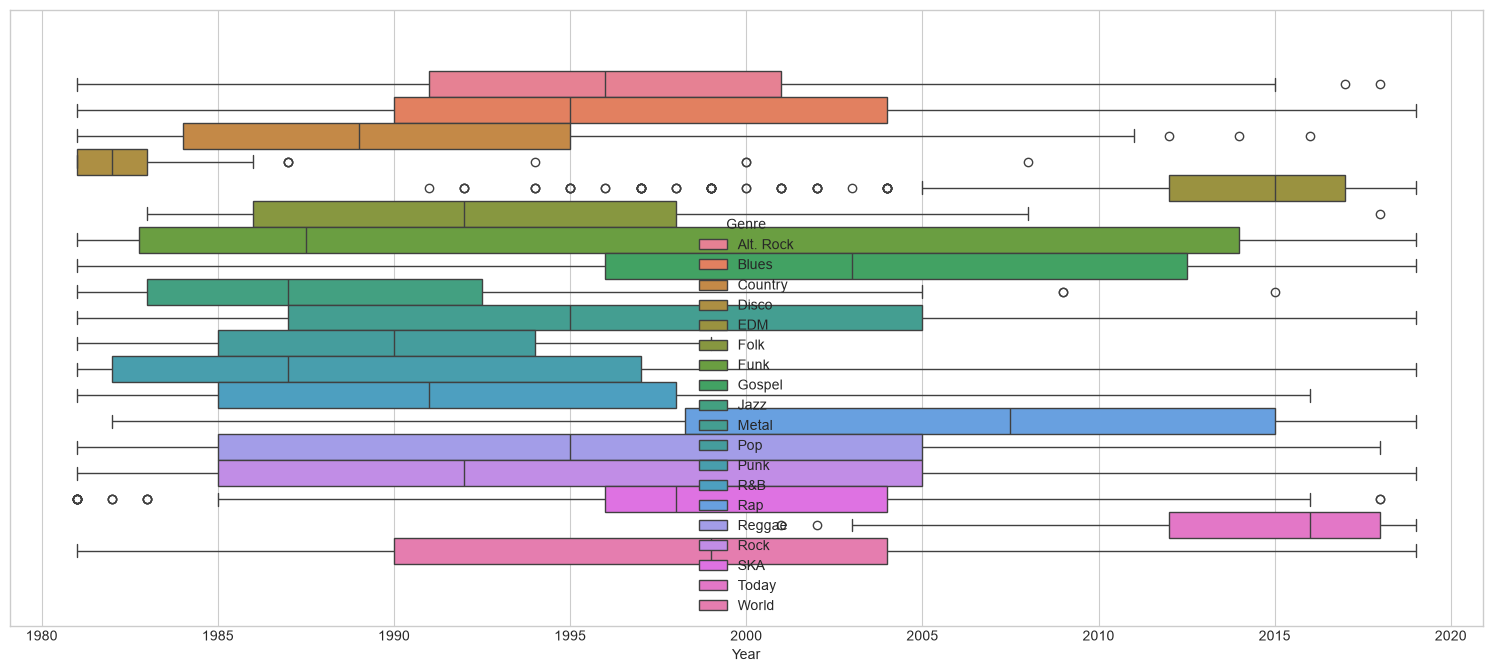

In [128]:
plt.figure(figsize=(19,8))

sns.boxplot(data = df, x = "Year" ,hue = "Genre")

## Matriz de correlaciones

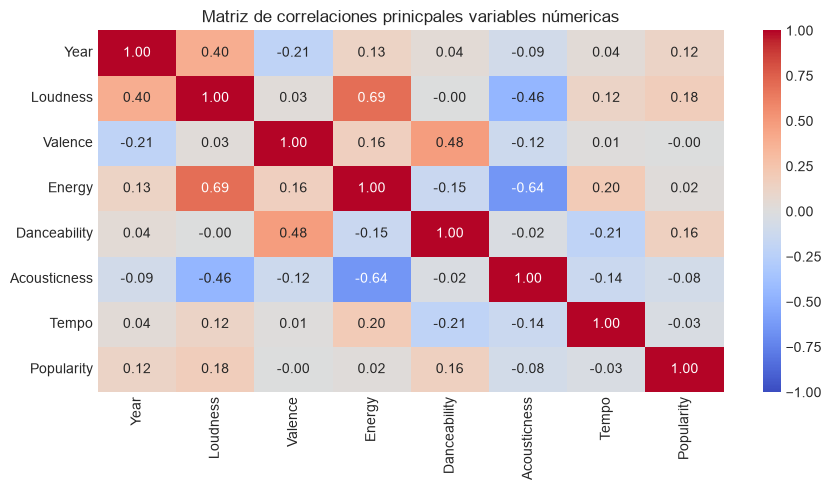

In [129]:
variables = [
    "Year",
    "Loudness",
    "Valence",
    "Energy",
    "Danceability",
    "Acousticness",
    "Tempo",
    "Popularity"
   
]

corr = df[variables].corr()

plt.figure(figsize=(9, 5))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0,
    vmin =-1
)

plt.title("Matriz de correlaciones prinicpales variables númericas")
plt.tight_layout()
plt.show()

### Loudness media a lo largo del tiempo

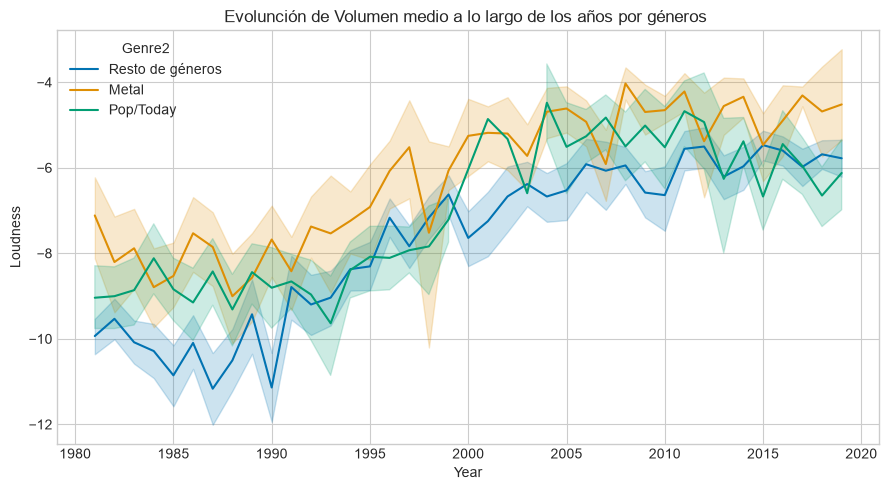

In [130]:
plt.figure(figsize=(9,5))



sns.lineplot(data = df, x = "Year", y = "Loudness", hue = "Genre2", palette = "colorblind")
plt.title("Evolunción de Volumen medio a lo largo de los años por géneros ")
plt.tight_layout()
plt.show()

Correlaciones con tiempo significativas

<Axes: xlabel='Loudness', ylabel='Genre2'>

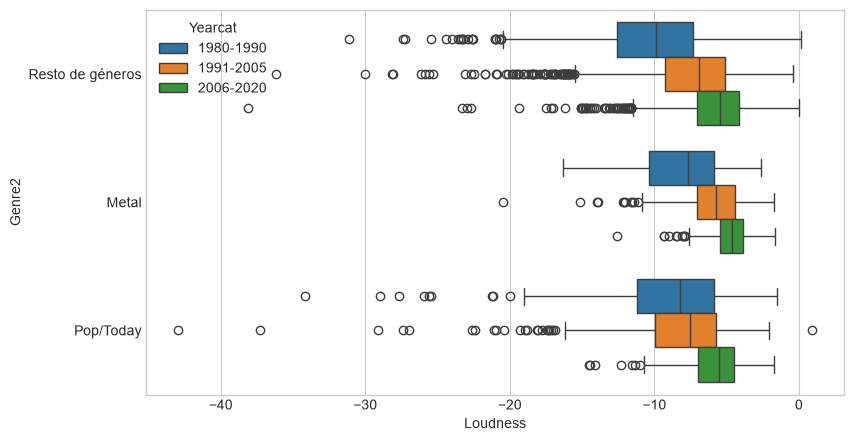

In [131]:
plt.figure(figsize=(9,5))

sns.boxplot(data = df, x = "Loudness", y= "Genre2" ,hue = "Yearcat")

In [133]:
resultados = []

for genero, subset in df.groupby("Genre"):
    r, p = pearsonr(subset["Loudness"], subset["Year"])

    if p < 0.01:
        resultados.append((genero, r, p))

for genero, r, p in sorted(resultados, key=lambda x: x[1], reverse=True):
    print(f"{genero}: R = {r:.3f}, p-value = {p:.4f}")



Metal: R = 0.532, p-value = 0.0000
Reggae: R = 0.512, p-value = 0.0000
Country: R = 0.468, p-value = 0.0000
Alt. Rock: R = 0.448, p-value = 0.0000
Blues: R = 0.411, p-value = 0.0000
Gospel: R = 0.409, p-value = 0.0000
Punk: R = 0.386, p-value = 0.0000
R&B: R = 0.376, p-value = 0.0000
Rock: R = 0.330, p-value = 0.0000
Funk: R = 0.325, p-value = 0.0001
Folk: R = 0.322, p-value = 0.0008
SKA: R = 0.316, p-value = 0.0000
EDM: R = 0.284, p-value = 0.0000
Rap: R = 0.260, p-value = 0.0000
World: R = 0.203, p-value = 0.0009
Pop: R = 0.088, p-value = 0.0003
Today: R = -0.198, p-value = 0.0013


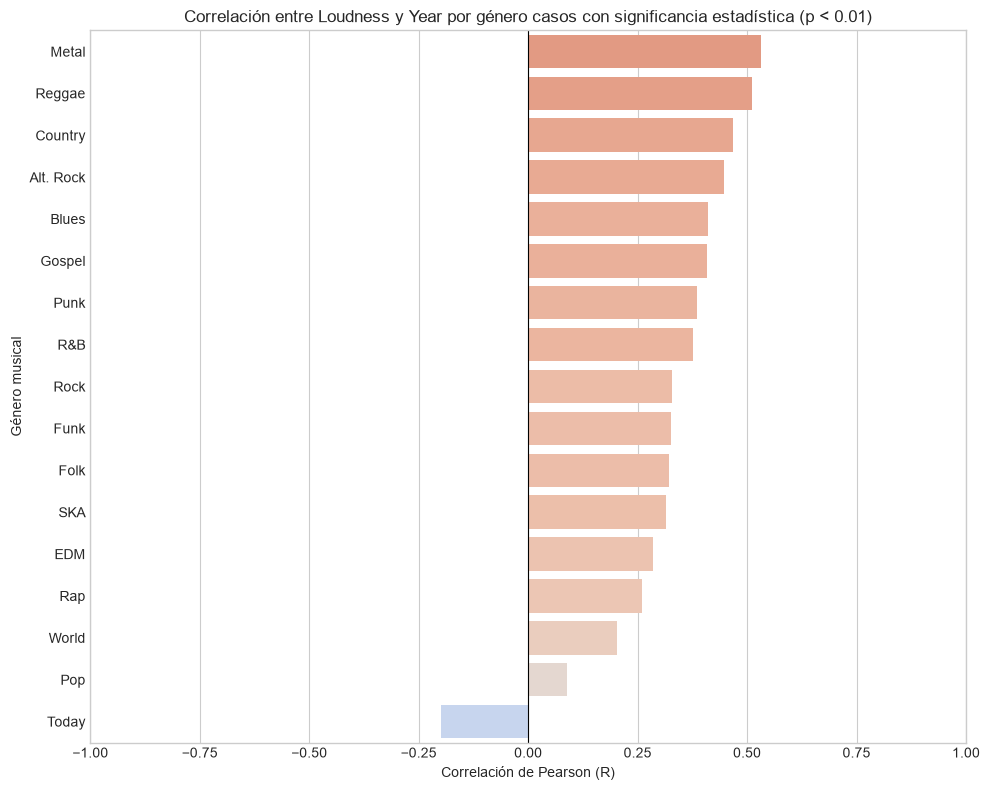

In [134]:


# Crear DataFrame y ordenar
corr_df = pd.DataFrame(resultados, columns=["Género", "R", "p-value"])
corr_df = corr_df.sort_values("R", ascending=False)

# Barplot
plt.figure(figsize=(10, 8))

sns.barplot(
    data=corr_df,
    x="R",
    y="Género",
    hue="R",
    palette="coolwarm",
    hue_norm=(-1, 1),
    dodge=False,
    legend=False
)

plt.axvline(0, color="black", linewidth=0.8)
plt.xlim(-1, 1)
plt.xlabel("Correlación de Pearson (R)")
plt.ylabel("Género musical")
plt.title("Correlación entre Loudness y Year por género casos con significancia estadística (p < 0.01)")

plt.tight_layout()
plt.show()

### Valence media a lo largo del tiempo

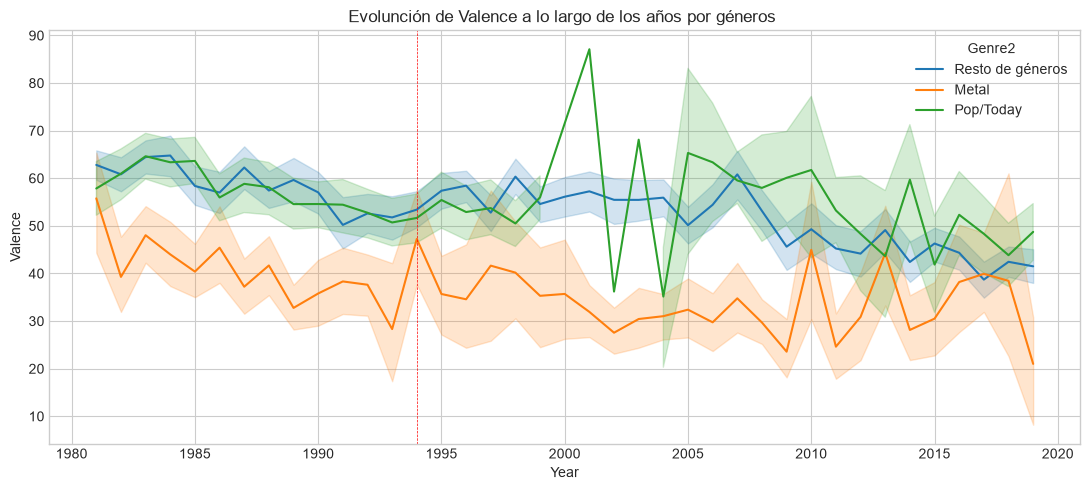

In [91]:

plt.figure(figsize=(11,5))

sns.lineplot(data = df, x = "Year", y = "Valence", hue = "Genre2")
plt.title("Evolunción de Valence a lo largo de los años por géneros ")
plt.tight_layout()
plt.axvline(x=1994, color='red', linestyle='--', linewidth=0.5)

plt.show()

Cambios de valence en funcion del género significagtivos

<Axes: xlabel='Valence', ylabel='Genre2'>

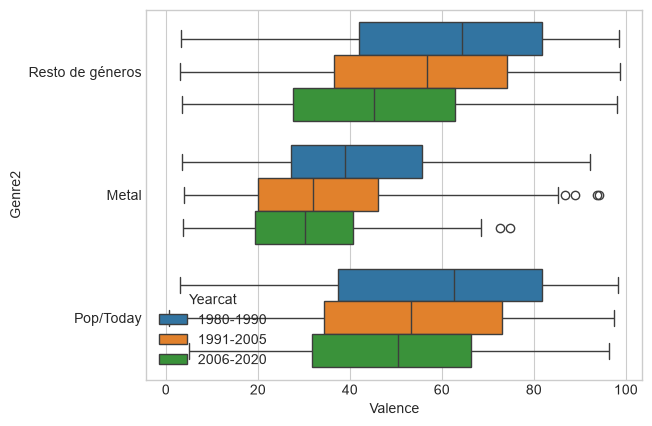

In [92]:
sns.boxplot(data = df, x = "Valence", y= "Genre2" ,hue = "Yearcat")

En el caso del metal se observa una pequeña alza de la postividad de las canciones entre poco depspues del año 2000 y mediados de la década. Esto concuerda con un periodo sociohistorico muy concreto. El periodo entre el 11-S y el comienzo del hastío con la guera de Irak.

Para analizar como afecto este fénomeno a la producción músical analizaremos dos géneros contrapuestos el Country y el Punkk

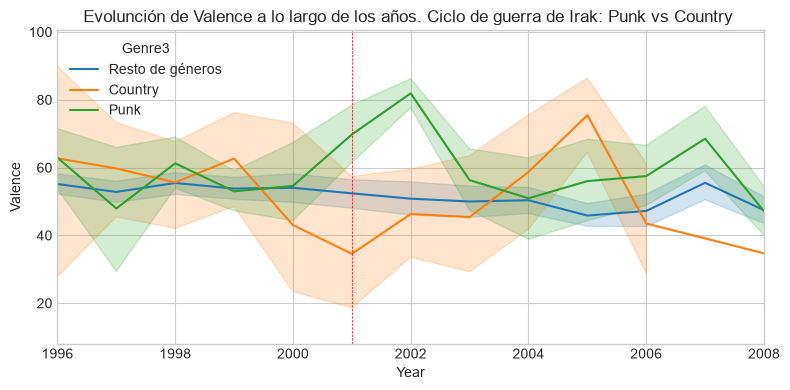

In [93]:

df["Genre3"] = np.select(
    [
        df["Genre"] == "Country",
        df["Genre"] == "Punk",

    
    ],
    [
        "Country",
        "Punk"

    ],
    default="Resto de géneros"
)
plt.figure(figsize=(8,4))
sns.lineplot(data = df, x = "Year", y = "Valence", hue = "Genre3")
plt.xlim(1996, 2008)
plt.title("Evolunción de Valence a lo largo de los años. Ciclo de guerra de Irak: Punk vs Country ")
plt.tight_layout()
plt.axvline(x=2001, color='red', linestyle='--', linewidth=0.5)

plt.show()

In [110]:
resultados = []

for genero, subset in df.groupby("Genre"):
    r, p = pearsonr(subset["Valence"], subset["Year"])

    if p < 0.01:
        resultados.append((genero, r, p))

for genero, r, p in sorted(resultados, key=lambda x: x[1], reverse=True):
    print(f"{genero}: R = {r:.3f}, p-value = {p:.4f}")

Punk: R = 0.212, p-value = 0.0000
Pop: R = -0.124, p-value = 0.0000
Today: R = -0.176, p-value = 0.0045
Gospel: R = -0.186, p-value = 0.0029
Rock: R = -0.204, p-value = 0.0000
Metal: R = -0.231, p-value = 0.0000
R&B: R = -0.240, p-value = 0.0002
Alt. Rock: R = -0.248, p-value = 0.0000
Funk: R = -0.359, p-value = 0.0000
Rap: R = -0.387, p-value = 0.0000


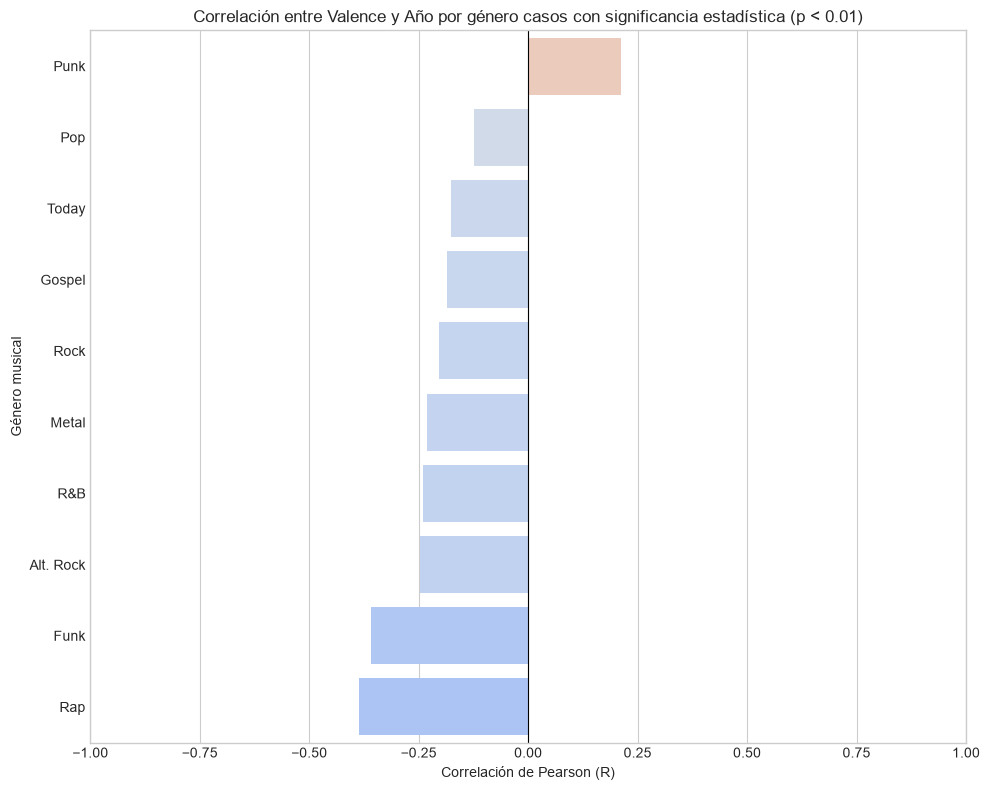

In [111]:
corr_df = pd.DataFrame(resultados, columns=["Género", "R", "p-value"])
corr_df = corr_df.sort_values("R", ascending=False)

plt.figure(figsize=(10, 8))

sns.barplot(
    data=corr_df,
    x="R",
    y="Género",
    hue="R",
    palette="coolwarm",
    hue_norm=(-1, 1),
    dodge=False,
    legend=False
)

plt.axvline(0, color="black", linewidth=0.8)
plt.xlim(-1, 1)
plt.xlabel("Correlación de Pearson (R)")
plt.ylabel("Género musical")
plt.title("Correlación entre Valence y Año por género casos con significancia estadística (p < 0.01)")

plt.tight_layout()
plt.show()

Cambios en el tiempo: Energía

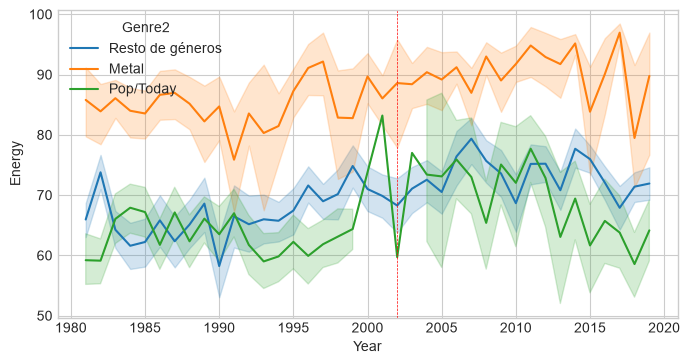

In [96]:
plt.figure(figsize=(8,4))

sns.lineplot(data = df, x = "Year", y = "Energy", hue = "Genre2")
plt.axvline(x=2002, color='red', linestyle='--', linewidth=0.5)




<Axes: xlabel='Energy', ylabel='Genre2'>

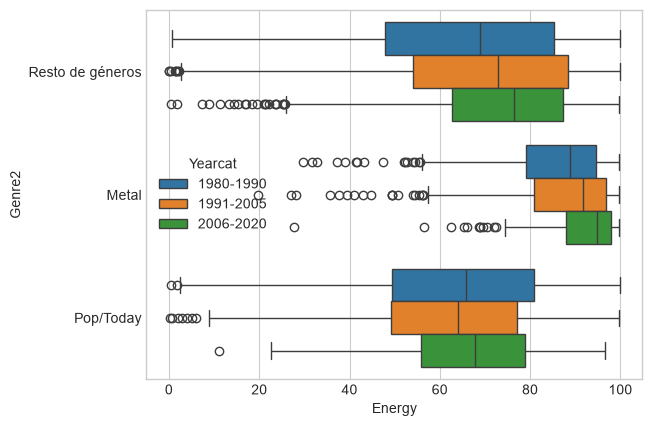

In [97]:
sns.boxplot(data = df, x = "Energy", y= "Genre2" ,hue = "Yearcat")

In [108]:
resultados = []

for genero, subset in df.groupby("Genre"):
    r, p = pearsonr(subset["Energy"], subset["Year"])

    if p < 0.01:
        resultados.append((genero, r, p))

for genero, r, p in sorted(resultados, key=lambda x: x[1], reverse=True):
    print(f"{genero}: R = {r:.3f}, p-value = {p:.4f}")

Reggae: R = 0.365, p-value = 0.0000
Country: R = 0.267, p-value = 0.0000
Metal: R = 0.192, p-value = 0.0000
Gospel: R = 0.184, p-value = 0.0032
SKA: R = 0.182, p-value = 0.0032
Alt. Rock: R = 0.181, p-value = 0.0000
EDM: R = -0.142, p-value = 0.0002
Rap: R = -0.143, p-value = 0.0002
Today: R = -0.241, p-value = 0.0001


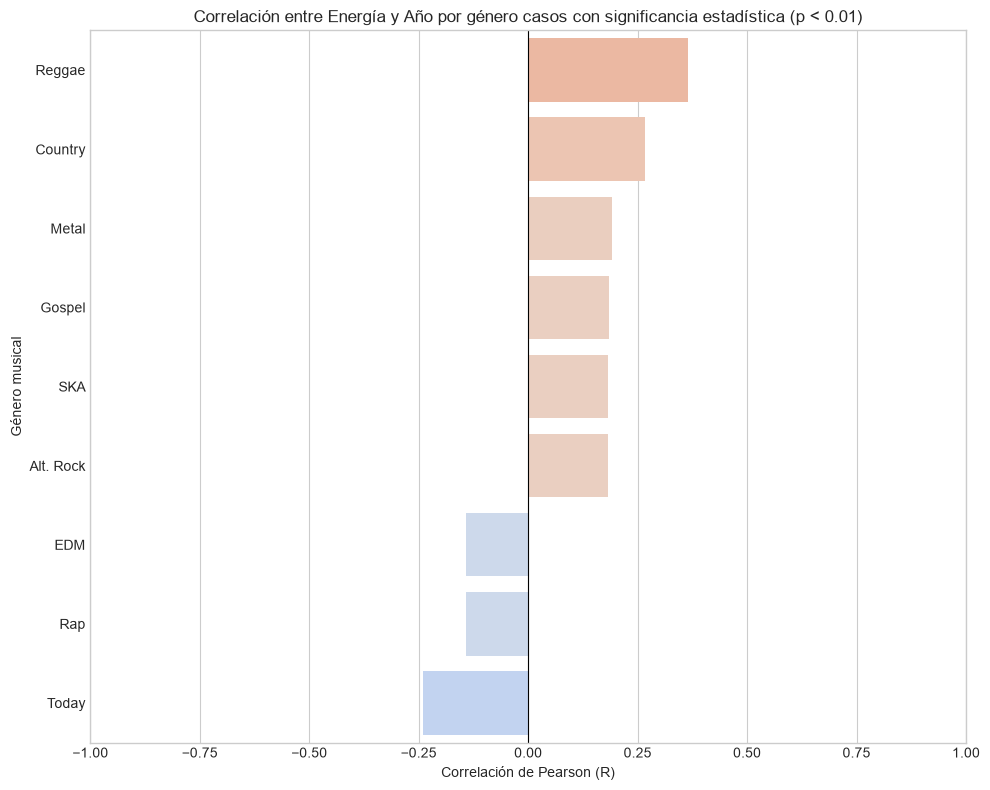

In [109]:
corr_df = pd.DataFrame(resultados, columns=["Género", "R", "p-value"])
corr_df = corr_df.sort_values("R", ascending=False)

plt.figure(figsize=(10, 8))

sns.barplot(
    data=corr_df,
    x="R",
    y="Género",
    hue="R",
    palette="coolwarm",
    hue_norm=(-1, 1),
    dodge=False,
    legend=False
)

plt.axvline(0, color="black", linewidth=0.8)
plt.xlim(-1, 1)
plt.xlabel("Correlación de Pearson (R)")
plt.ylabel("Género musical")
plt.title("Correlación entre Energía y Año por género casos con significancia estadística (p < 0.01)")

plt.tight_layout()
plt.show()

Evolución: Acustica 

In [100]:
resultados = []

for genero, subset in df.groupby("Genre"):
    r, p = pearsonr(subset["Acousticness"], subset["Year"])

    if p < 0.01:
        resultados.append((genero, r, p))

for genero, r, p in sorted(resultados, key=lambda x: x[1], reverse=True):
    print(f"{genero}: R = {r:.3f}, p-value = {p:.4f}")

Rap: R = 0.183, p-value = 0.0000
Alt. Rock: R = -0.142, p-value = 0.0002
Metal: R = -0.167, p-value = 0.0000
Gospel: R = -0.277, p-value = 0.0000


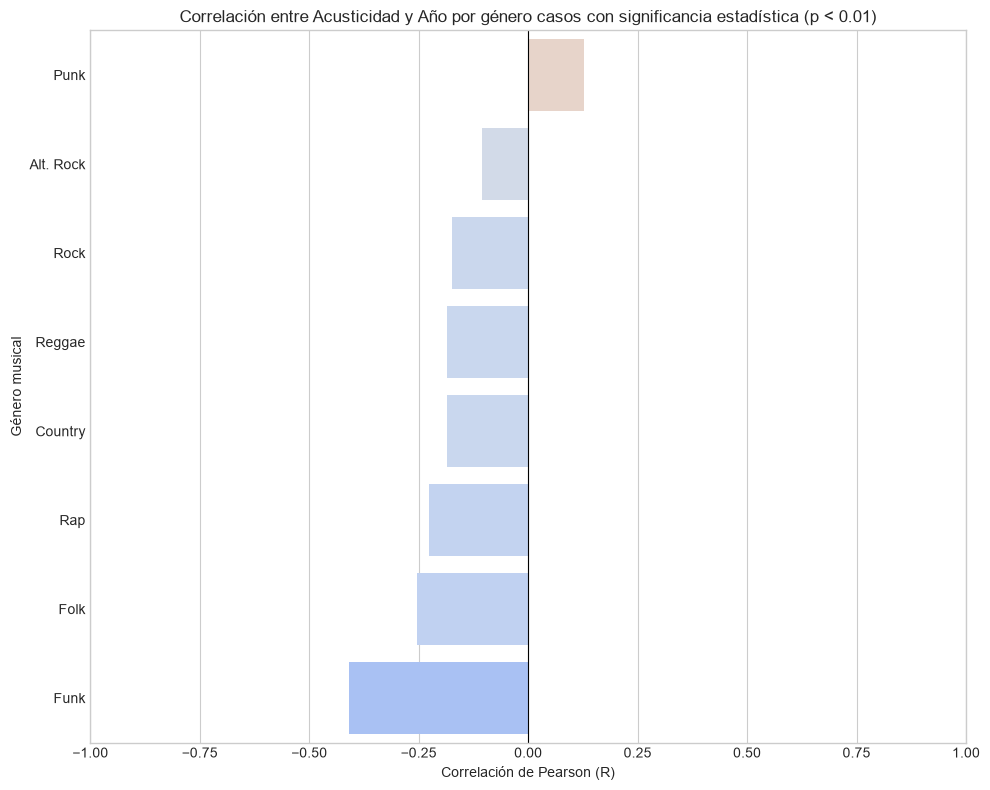

In [107]:
corr_df = pd.DataFrame(resultados, columns=["Género", "R", "p-value"])
corr_df = corr_df.sort_values("R", ascending=False)

plt.figure(figsize=(10, 8))

sns.barplot(
    data=corr_df,
    x="R",
    y="Género",
    hue="R",
    palette="coolwarm",
    hue_norm=(-1, 1),
    dodge=False,
    legend=False
)

plt.axvline(0, color="black", linewidth=0.8)
plt.xlim(-1, 1)
plt.xlabel("Correlación de Pearson (R)")
plt.ylabel("Género musical")
plt.title("Correlación entre Acusticidad y Año por género casos con significancia estadística (p < 0.01)")

plt.tight_layout()
plt.show()

Evolucion del Modo

In [102]:
resultados = []

for genero, subset in df.groupby("Genre"):
    r, p = pearsonr(subset["Mode"], subset["Year"])

    if p < 0.01:
        resultados.append((genero, r, p))

for genero, r, p in sorted(resultados, key=lambda x: x[1], reverse=True):
    print(f"{genero}: R = {r:.3f}, p-value = {p:.4f}")

Reggae: R = -0.193, p-value = 0.0018


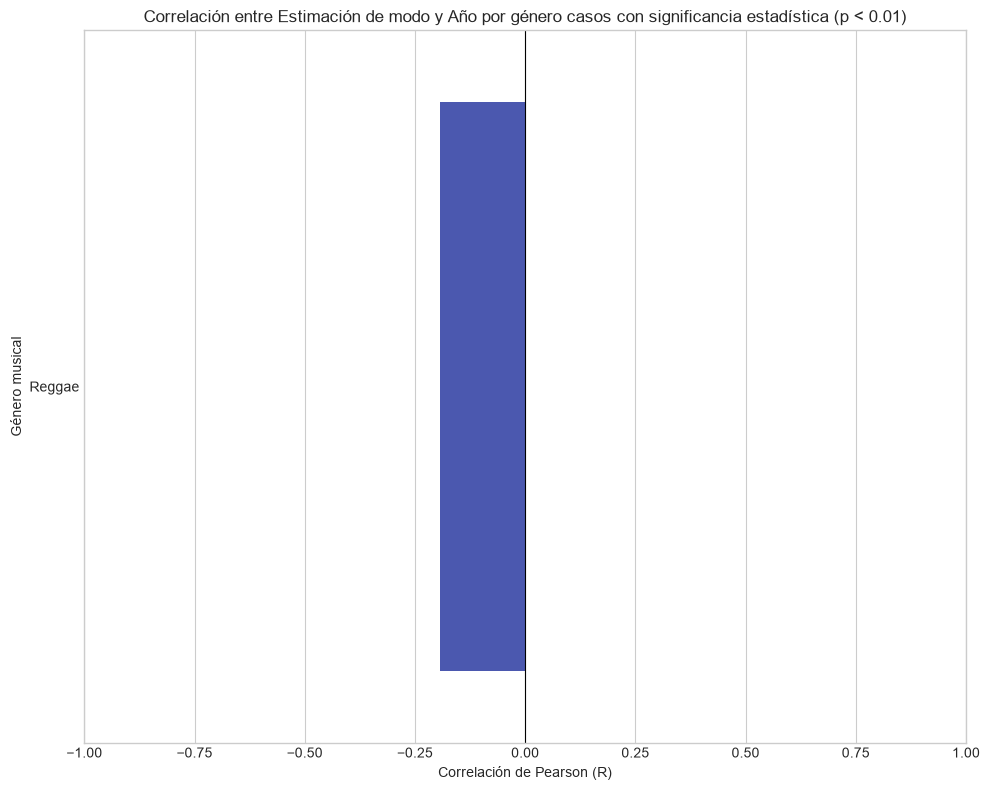

In [ ]:
corr_df = pd.DataFrame(resultados, columns=["Género", "R", "p-value"])
corr_df = corr_df.sort_values("R", ascending=False)

plt.figure(figsize=(10, 8))

sns.barplot(
    data=corr_df,
    x="R",
    y="Género",
    hue="R",
    palette="coolwarm",
    dodge=False,
    hue_norm=(-1, 1),
    legend=False
)

plt.axvline(0, color="black", linewidth=0.8)
plt.xlim(-1, 1)
plt.xlabel("Correlación de Pearson (R)")
plt.ylabel("Género musical")
plt.title("Correlación entre Estimación de modo y Año por género casos con significancia estadística (p < 0.01)")

plt.tight_layout()
plt.show()

Evolucion de Bailabilidad

In [105]:
resultados = []

for genero, subset in df.groupby("Genre"):
    r, p = pearsonr(subset["Danceability"], subset["Year"])

    if p < 0.01:
        resultados.append((genero, r, p))

for genero, r, p in sorted(resultados, key=lambda x: x[1], reverse=True):
    print(f"{genero}: R = {r:.3f}, p-value = {p:.4f}")

Punk: R = 0.128, p-value = 0.0028
Alt. Rock: R = -0.104, p-value = 0.0066
Rock: R = -0.175, p-value = 0.0002
Reggae: R = -0.185, p-value = 0.0029
Country: R = -0.186, p-value = 0.0018
Rap: R = -0.227, p-value = 0.0000
Folk: R = -0.255, p-value = 0.0088
Funk: R = -0.410, p-value = 0.0000


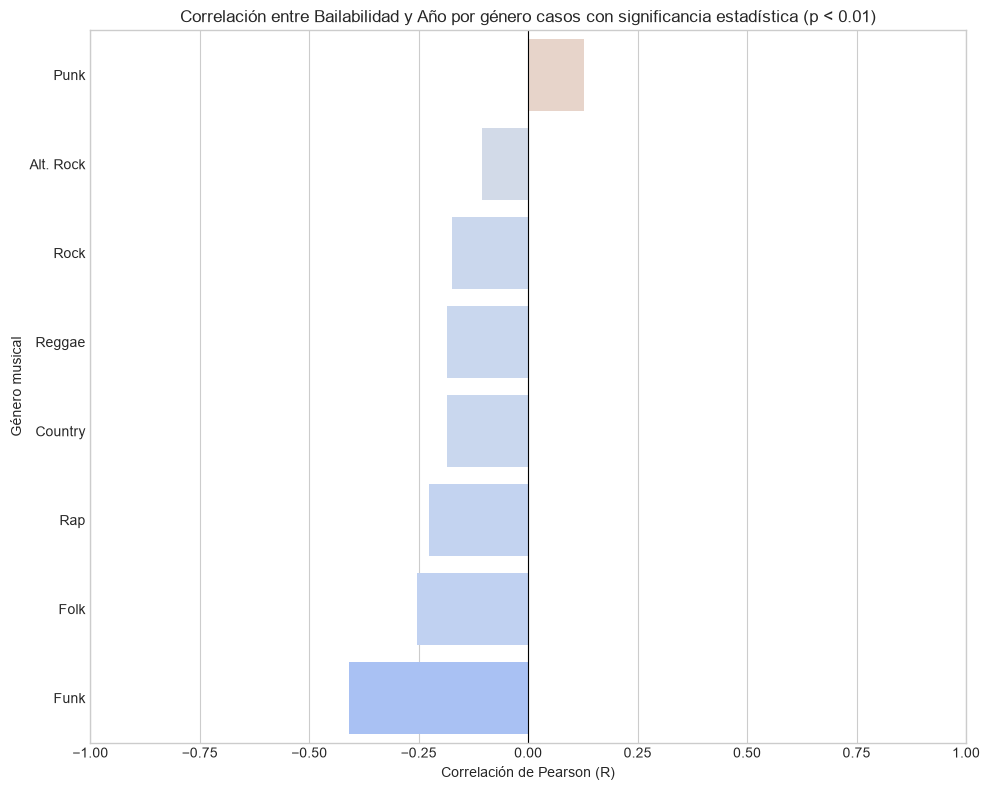

In [106]:
corr_df = pd.DataFrame(resultados, columns=["Género", "R", "p-value"])
corr_df = corr_df.sort_values("R", ascending=False)

plt.figure(figsize=(10, 8))

sns.barplot(
    data=corr_df,
    x="R",
    y="Género",
    hue="R",
    palette="coolwarm",
    hue_norm=(-1, 1),
    dodge=False,
    legend=False
)

plt.axvline(0, color="black", linewidth=0.8)
plt.xlim(-1, 1)
plt.xlabel("Correlación de Pearson (R)")
plt.ylabel("Género musical")
plt.title("Correlación entre Bailabilidad y Año por género casos con significancia estadística (p < 0.01)")

plt.tight_layout()
plt.show()

Evolucion del tempo

In [41]:
resultados = []

for genero, subset in df.groupby("Genre"):
    r, p = pearsonr(subset["Tempo"], subset["Year"])

    if p < 0.01:
        resultados.append((genero, r, p))

for genero, r, p in sorted(resultados, key=lambda x: x[1], reverse=True):
    print(f"{genero}: R = {r:.3f}, p-value = {p:.4f}")

Rap: R = 0.280, p-value = 0.0000


In [ ]:
corr_df = pd.DataFrame(resultados, columns=["Género", "R", "p-value"])
corr_df = corr_df.sort_values("R", ascending=False)

plt.figure(figsize=(10, 8))

sns.barplot(
    data=corr_df,
    x="R",
    y="Género",
    hue="R",
    hue_norm=(-1, 1),
    palette="coolwarm",
    dodge=False,
    legend=False
)

plt.axvline(0, color="black", linewidth=0.8)
plt.xlim(-1, 1)
plt.xlabel("Correlación de Pearson (R)")
plt.ylabel("Género musical")
plt.title("Correlación entre Tempo y Año por género casos con significancia estadística (p < 0.01)")

plt.tight_layout()
plt.show()

# Popularidad y géneros

Fecha y popularidad por género

In [67]:
resultados = []

for genero, subset in df.groupby("Genre"):
    r, p = pearsonr(subset["Popularity"], subset["Year"])

    if p < 0.01:
        resultados.append((genero, r, p))

for genero, r, p in sorted(resultados, key=lambda x: x[1], reverse=True):
    print(f"{genero}: R = {r:.3f}, p-value = {p:.4f}")

Gospel: R = 0.346, p-value = 0.0000
Reggae: R = 0.338, p-value = 0.0000
Rap: R = 0.337, p-value = 0.0000
Country: R = 0.312, p-value = 0.0000
Alt. Rock: R = 0.270, p-value = 0.0000
Punk: R = 0.217, p-value = 0.0000
Rock: R = -0.224, p-value = 0.0000


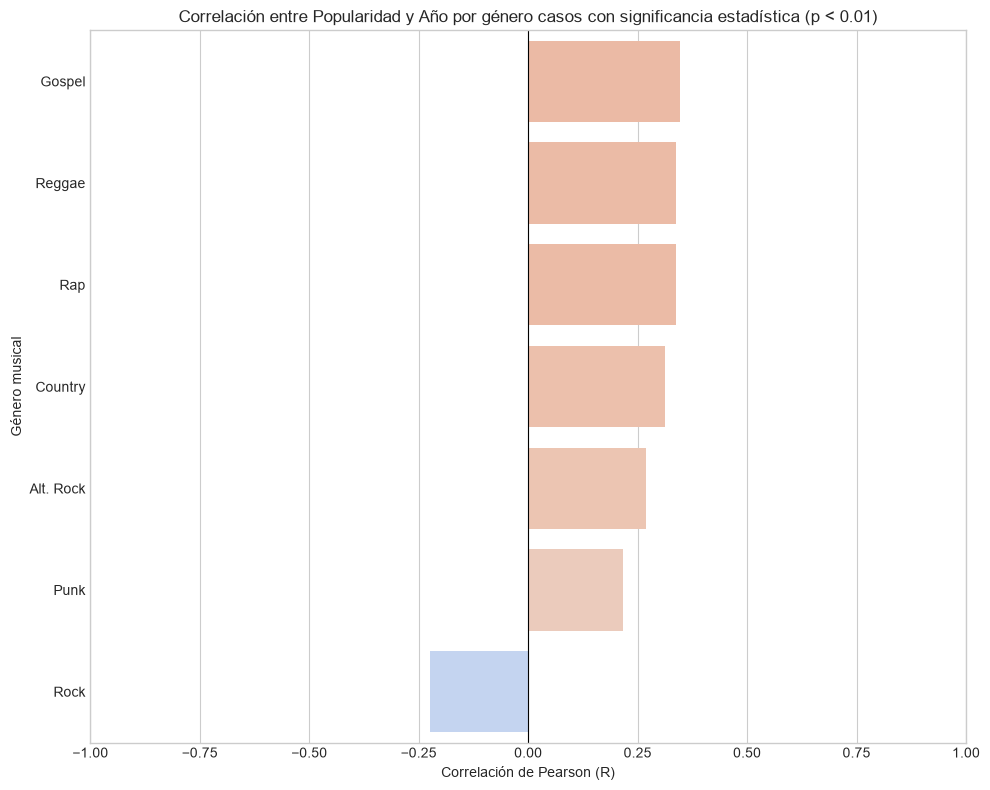

In [68]:
corr_df = pd.DataFrame(resultados, columns=["Género", "R", "p-value"])
corr_df = corr_df.sort_values("R", ascending=False)

plt.figure(figsize=(10, 8))

sns.barplot(
    data=corr_df,
    x="R",
    y="Género",
    hue="R",
    palette="coolwarm",
    hue_norm=(-1, 1),
    dodge=False,
    legend=False
)

plt.axvline(0, color="black", linewidth=0.8)
plt.xlim(-1, 1)
plt.xlabel("Correlación de Pearson (R)")
plt.ylabel("Género musical")
plt.title("Correlación entre Popularidad y Año por género casos con significancia estadística (p < 0.01)")

plt.tight_layout()
plt.show()

valence y popularidad por genero 

In [62]:
resultados = []

for genero, subset in df.groupby("Genre"):
    r, p = pearsonr(subset["Popularity"], subset["Valence"])

    if p < 0.01:
        resultados.append((genero, r, p))

for genero, r, p in sorted(resultados, key=lambda x: x[1], reverse=True):
    print(f"{genero}: R = {r:.3f}, p-value = {p:.4f}")

Punk: R = 0.187, p-value = 0.0000
Metal: R = 0.161, p-value = 0.0000
EDM: R = 0.148, p-value = 0.0001
Rap: R = -0.149, p-value = 0.0001
Gospel: R = -0.253, p-value = 0.0000


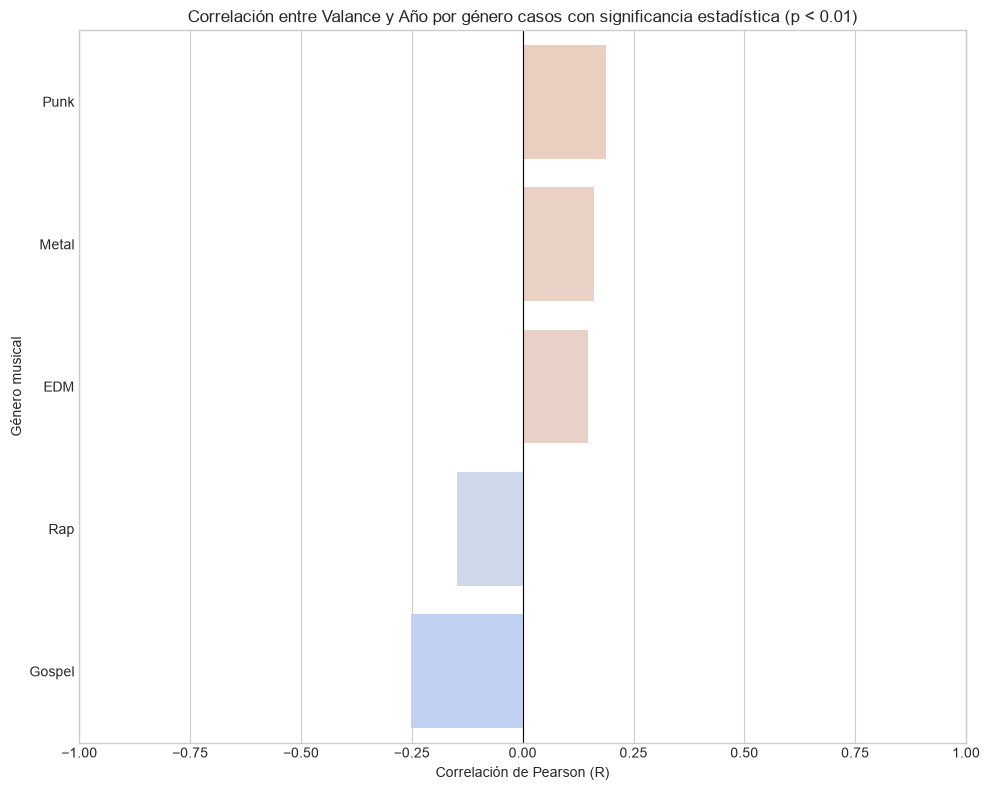

In [66]:
corr_df = pd.DataFrame(resultados, columns=["Género", "R", "p-value"])
corr_df = corr_df.sort_values("R", ascending=False)

plt.figure(figsize=(10, 8))

sns.barplot(
    data=corr_df,
    x="R",
    y="Género",
    hue="R",
    hue_norm=(-1, 1),
    palette="coolwarm",
    dodge=False,
    legend=False
)

plt.axvline(0, color="black", linewidth=0.8)
plt.xlim(-1, 1)
plt.xlabel("Correlación de Pearson (R)")
plt.ylabel("Género musical")
plt.title("Correlación entre Valance y Año por género casos con significancia estadística (p < 0.01)")

plt.tight_layout()
plt.show()

loudness y popularidad por género

In [29]:
resultados = []

for genero, subset in df.groupby("Genre"):
    r, p = pearsonr(subset["Popularity"], subset["Loudness"])

    if p < 0.01:
        resultados.append((genero, r, p))

for genero, r, p in sorted(resultados, key=lambda x: x[1], reverse=True):
    print(f"{genero}: R = {r:.3f}, p-value = {p:.4f}")

Alt. Rock: R = 0.259, p-value = 0.0000
Reggae: R = 0.243, p-value = 0.0001
Gospel: R = 0.237, p-value = 0.0001
Country: R = 0.232, p-value = 0.0001
Metal: R = 0.192, p-value = 0.0000
Rap: R = 0.171, p-value = 0.0000
Pop: R = 0.119, p-value = 0.0000


Energy y popularidad por génreo

In [28]:
resultados = []

for genero, subset in df.groupby("Genre"):
    r, p = pearsonr(subset["Popularity"], subset["Energy"])

    if p < 0.01:
        resultados.append((genero, r, p))

for genero, r, p in sorted(resultados, key=lambda x: x[1], reverse=True):
    print(f"{genero}: R = {r:.3f}, p-value = {p:.4f}")

Country: R = 0.229, p-value = 0.0001
Reggae: R = 0.183, p-value = 0.0032
Alt. Rock: R = 0.166, p-value = 0.0000
Rap: R = -0.133, p-value = 0.0005
EDM: R = -0.259, p-value = 0.0000


Bailabilidad y populariad


In [27]:
resultados = []

for genero, subset in df.groupby("Genre"):
    r, p = pearsonr(subset["Popularity"], subset["Danceability"])

    if p < 0.01:
        resultados.append((genero, r, p))

for genero, r, p in sorted(resultados, key=lambda x: x[1], reverse=True):
    print(f"{genero}: R = {r:.3f}, p-value = {p:.4f}")

Metal: R = 0.221, p-value = 0.0000
Punk: R = 0.136, p-value = 0.0015
EDM: R = 0.128, p-value = 0.0009
